# **EDA: разведочный анализ данных текстовых данных**

## **Описание проекта**

**Описание данных**:

Для построения модели воспользуемся датасетом от Яндекса с отзывами и оценками пользователей к конкретным местам. Снизим размерность датасета путем выбора определенных рубрик, в нашем случае это будет ритейл, т. к. область, в которой изначально планировалось применять модель - это ритейл.

**Практическое применение**:

В клиентской аналитике существует ряд метрик, характеризующих лояльность клиентов/покупателей, например, NPS (Net Promoter Score) или CSAT (Customer Satisfaction Rate). Для получения этих оценок бизнес рассылает опросы, где покупатели могут не только поставить оценку, но и оставить комментарий с жалобой или, наоборот, с комплиментами. Эти комментарии в дальнейшем могут использоваться бизнесом для сбора статистики о количестве позитивных/негативных/нейтральных отзывов за какой-либо промежуток времени.

Однако иногда комментарий и оценка не соответствуют друг другу, например, из-за того, что покупатель случайно поставил не ту оценку, или вовсе написал несуразный комментарий, который не совсем понятно как воспринимать, текст совсем неинформативный: это может быть набор рандомных символов, эмодзи, сарказм, пустая строка и т. п. Несмотря на это, полученные оценки все равно "подтягиваются" скриптами в расчеты, а отзывы некорректно разделяются на подгруппы, т. к. модель никак не фильтрует такие кейсы. На больших массивах данных эти аномальные случаи действительно не играют значимой роли, но в локальных исследованиях, где анализ выполняется на небольшой выборке, из-за таких оценок итоговая метрика может ощутимо завышаться/занижаться, а бизнес получает ложное представление о лояльности покупателей.

**Цель исследования**:

Для получения корректной метрики можно составить алгоритм, который будет находить такие аномальные случаи и либо выкидывать их из расчетов полностью, либо "додумывать" приблизительную оценку. На данном этапе это пока две основные цели, которые будет решать наша модель, однако они могут быть скорректированы в зависимости от хода исследования.

## **Библиотеки**

In [ ]:
# Загрузка новых библиотек
!pip install emoji --q
!pip install phik --q

In [ ]:
# Загрузка библиотек
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
import phik

from transformers import pipeline
from tqdm.auto import tqdm

import nltk
from nltk.corpus import stopwords
import emoji
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sentence_transformers import SentenceTransformer
import hdbscan
import time

In [ ]:
# Отдельно загружаем стоп-слова в русском языке
nltk.download('stopwords')
russian_stop_words = stopwords.words('russian')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## **Загрузка и обзор первоначальных данных**

**Описание**: На данном этапе мы ничего не анализируем, но все же знакомимся с изначальными данными, их объемом и составом признаков.

In [ ]:
# Загрузка и обзор данных
df = pd.read_parquet("hf://datasets/d0rj/geo-reviews-dataset-2023/data/train-00000-of-00001-49261e4e5a35a5a0.parquet")
df.head()

,address,name_ru,rating,rubrics,text
0,"Екатеринбург, ул. Московская / ул. Волгоградск...",Московский квартал,3,Жилой комплекс,Московский квартал 2.\nШумно : летом по ночам ...
1,"Московская область, Электросталь, проспект Лен...",Продукты Ермолино,5,Магазин продуктов;Продукты глубокой заморозки;...,"Замечательная сеть магазинов в общем, хороший ..."
2,"Краснодар, Прикубанский внутригородской округ,...",LimeFit,1,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я..."
3,"Санкт-Петербург, проспект Энгельса, 111, корп. 1",Snow-Express,4,Пункт проката;Прокат велосипедов;Сапсёрфинг,Хорошие условия аренды. \nДружелюбный персонал...
4,"Тверь, Волоколамский проспект, 39",Студия Beauty Brow,5,"Салон красоты;Визажисты, стилисты;Салон бровей...",Топ мастер Ангелина топ во всех смыслах ) Немн...


In [ ]:
# Размерность данных
df.shape

(500000, 5)

In [ ]:
# Общее инфо о данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   address  500000 non-null  object
 1   name_ru  499030 non-null  object
 2   rating   500000 non-null  int64 
 3   rubrics  500000 non-null  object
 4   text     500000 non-null  object
dtypes: int64(1), object(4)
memory usage: 19.1+ MB


In [ ]:
# Наличие пропусков
df.isnull().sum()

,0
address,0
name_ru,970
rating,0
rubrics,0
text,0


In [ ]:
# Наличие явных дубликатов
df.duplicated().sum()

np.int64(1)

**Промежуточный вывод**: В датасете ровно 500 тыс. оценок с комментариями и 5 признаков, 4 из которых категориальные и 1 - числовая (сам рейтинг). В датасете 970 пропусков в столбце `name_ru` и 1 пара полных дубликатов, однако после фильтрации комментариев в области ритейл объем данных уменьшится, и мы получим совершенно другие результаты - на этих данных и сосредоточимся.




## **Сбор данных из ритейла**

**Описание**: На данном этапе мы собираем ту выборку, которую будем использовать на протяжении всего анализа.

In [ ]:
# Столбец с рубриками
print(f'Количество уникальных значений в колонке: {df['rubrics'].nunique()}')
df['rubrics'].unique()

Количество уникальных значений в колонке: 31793


array(['Жилой комплекс',
       'Магазин продуктов;Продукты глубокой заморозки;Магазин мяса, колбас',
       'Фитнес-клуб', ...,
       'Веломагазин;Ремонт велосипедов;Оптовая компания',
       'Шиномонтаж;Шины и диски;Автосвет',
       'Школа танцев;Студия йоги;Стретчинг'], shape=(31793,), dtype=object)

In [ ]:
# Обработка и подсчет уникальных рубрик в столбце
df_unique_rubrics = df['rubrics'].str.split(';').explode().str.strip().to_frame(name='rubrics')
df_unique_rubrics = df_unique_rubrics[df_unique_rubrics['rubrics'] != ''].drop_duplicates().reset_index(drop=True)

print(f'Число уникальных рубрик/тематик: {len(df_unique_rubrics)}')

Число уникальных рубрик/тематик: 1370


In [ ]:
# df_unique_rubrics.to_excel('unique_rubrics.xlsx', index=False)

In [ ]:
# Выбор рубрик (был загружен датасет и вручную отобраны рубрики)
rubrics = [
    'Магазин продуктов', 'Продукты глубокой заморозки', 'Магазин мяса, колбас',
    'Кафе', 'Кофейня', 'Кондитерская', 'Ресторан', 'Быстрое питание',
    'Доставка еды и обедов', 'Пекарня', 'Столовая', 'Супермаркет',
    'Бар, паб', 'Магазин рыбы и морепродуктов', 'Магазин овощей и фруктов',
    'Молочный магазин', 'Суши-бар', 'Кофе с собой', 'Доставка продуктов',
    'Магазин алкогольных напитков', 'Магазин суши и азиатских продуктов',
    'Интернет-кафе', 'Пиццерия', 'Торты на заказ', 'Продуктовый рынок',
    'Мороженое', 'Безалкогольный бар', 'Пищевые ингредиенты и специи',
    'Магазин пива', 'Продуктовый гипермаркет', 'Гипермаркет',
    'Магазин чая', 'Яйцо и мясо птицы', 'Магазин сыров', 'Магазин кофе',
    'Мука и крупы', 'Диетические и диабетические продукты',
    'Производство продуктов питания', 'Спортивное питание',
    'Безалкогольные напитки', 'Молочная кухня', 'Мёд и продукты пчеловодства',
    'Орехи, снеки, сухофрукты', 'Кофейный автомат', 'Магазин детского питания',
    'Товары народного потребления', 'Винная ярмарка', 'Продуктовый автомат'
]

rubrics_lower = [rubric.lower() for rubric in rubrics]
new_df = df[df['rubrics'].apply(lambda text: any(rubric in text.lower() for rubric in rubrics_lower))].copy()

print(f'Размер нового датасета: {len(new_df)}')
print(f'Размер выборки от исходного датасета: {len(new_df) / len(df) * 100:.1f}%')

Размер нового датасета: 163479
Размер выборки от исходного датасета: 32.7%


**Промежуточный вывод:**

Была проведена фильтрация по исследуемому направлению. Исходный столбец с рубриками содержал более 31 тыс. уникальных комбинаций, причем в одной строке могло содержаться несколько рубрик, записанных через точку с запятой. По этой причине рубрики были разбиты по разделителю, очищены от пропусков и дубликатов, и как результат это позволило выделить 1 370 уникальных категорий.

Из них вручную был сформирован пул из 48 рубрик, относящихся к ритейлу и общепиту. В итоге был сформирован новый датасет объемом около 164 тыс. записей, что составляет практически треть от исходной выборки.

Таким образом мы получили срез данных, который соответствует поставленной задаче, и именно с этим набором данных мы будем работать далее.

### **Диагностика данных**

**Описание**: На данном этапе мы не только анализируем данные с точки зрения их качества и статистических характеристик, но и ставим перед собой некоторые гипотезы о том, с какими интересными/аномальными кейсами в текстовых обращениях мы можем столкнуться.  

In [ ]:
# Обзор датасета
new_df.head()

,address,name_ru,rating,rubrics,text
1,"Московская область, Электросталь, проспект Лен...",Продукты Ермолино,5,Магазин продуктов;Продукты глубокой заморозки;...,"Замечательная сеть магазинов в общем, хороший ..."
6,"Воронежская область, Богучарский район, М-4 До...",У тещи,4,Кафе,Глубинка страны во всех своих проявлениях. Асс...
8,"Москва, 4-й Кожевнический переулок, 4",Jinju,5,Кафе;Кофейня,"5 из 5🖤 Пил кофе и в Риме, и в Париже, но вку..."
9,"Москва, 4-й Кожевнический переулок, 4",Jinju,4,Кафе;Кофейня,"Не очень удобное расположение, от метро идти м..."
12,"Кемерово, проспект Ленина, 59А",Прованс,5,Кондитерская,Вкусное место в центре города. Разнообразное ...


In [ ]:
# Инфо о данных
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 163479 entries, 1 to 499997
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   address  163479 non-null  object
 1   name_ru  163208 non-null  object
 2   rating   163479 non-null  int64 
 3   rubrics  163479 non-null  object
 4   text     163479 non-null  object
dtypes: int64(1), object(4)
memory usage: 7.5+ MB


In [ ]:
# Наличие пропусков
print('Количество пустых строк')
print(new_df.isnull().sum())
print()

# Наличие явных дубликатов
print(f'Количество явных дубликатов: {new_df.duplicated().sum()}')

Количество пустых строк
address      0
name_ru    271
rating       0
rubrics      0
text         0
dtype: int64

Количество явных дубликатов: 0


In [ ]:
# Дубли комментариев: один текст, разные оценки
duplicated_comms = new_df.groupby('text')['rating'].nunique()
print(f'Количество задублированных комментариев: {(duplicated_comms > 1).sum()}')

duplicated_comms_rows = duplicated_comms[duplicated_comms > 1]
print(duplicated_comms_rows)

Количество задублированных комментариев: 3
text
Вкусно и не дорого    2
Хорошее заведение     2
Хороший магазин.      2
Name: rating, dtype: int64


In [ ]:
# Количество уникальных значений в колонках
for col in ['name_ru', 'rubrics']:
    print(f'Количество уникальных значений в колонке {col}: {new_df[col].nunique()}')
    print(f'Топ-10 {col} в датасете:')
    print(new_df[col].value_counts().head(10).sort_values(ascending=False))
    print()

Количество уникальных значений в колонке name_ru: 34296
Топ-10 name_ru в датасете:
name_ru
Пятёрочка           6029
Магнит              2592
Красное&Белое       1732
Вкусно — и точка    1181
Перекрёсток         1137
Леруа Мерлен         889
Дикси                879
Продукты             875
Чижик                739
Светофор             715
Name: count, dtype: int64

Количество уникальных значений в колонке rubrics: 5186
Топ-10 rubrics в датасете:
rubrics
Ресторан                                                            14615
Кафе                                                                12366
Супермаркет                                                          8899
Магазин продуктов                                                    5289
Быстрое питание                                                      4902
Ресторан;Кафе                                                        4554
Супермаркет;Магазин продуктов                                        4541
Кафе;Ресторан           

**Промежуточный вывод:** Для начала была проведена оценка базового качества выборки. Выявлены незначительные пропуски в столбце `name_ru`, составляющие менее 1% от всего объема данных, что некритично, так как основная информация содержится в самих текстах. Явных дубликатов строк не обнаружено, но есть дубли именно в колонке с комментариями: они достаточно типичные, т. е. клиенты просто хотели в целом написать о своих впечатлениях и использовали общие фразы. Это имеет место быть, но сомнительно, стоит ли оставлять такие дубли текстов в обучении. Наконец, анализ показал разнообразие заведений и рубрик в данных: 34 296 уникальных названий заведений и 5 186 уникальных комбинаций рубрик. Таким образом, мы убедились, что данные пригодны для дальнейшего анализа.

         count   share
rating                
5       121023  74.03%
4        16635  10.18%
1        11354   6.95%
3         9237   5.65%
2         5157   3.15%
0           73   0.04%



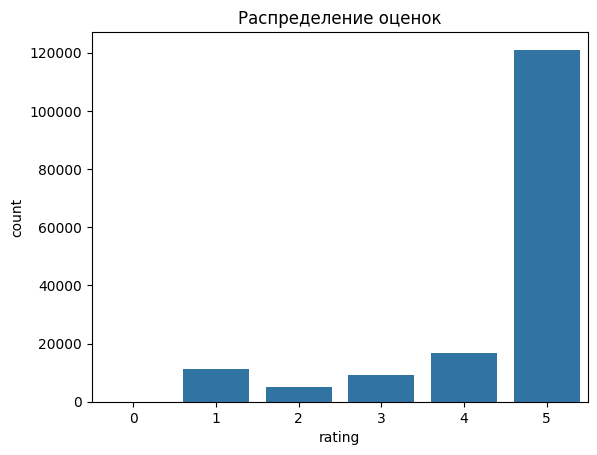

In [ ]:
# Распределение оценок
counts = new_df['rating'].value_counts()
shares = new_df['rating'].value_counts(normalize=True)

print(pd.concat([counts, shares.map('{:.2%}'.format)], axis=1, keys=['count', 'share']))
print()

sns.countplot(data=new_df, x='rating')
plt.title('Распределение оценок')
plt.show()

Статистика по длине текста:
count    163479.000000
mean        260.348063
std         234.009333
min           5.000000
25%         131.000000
50%         192.000000
75%         310.000000
max        6612.000000
Name: text_length, dtype: float64



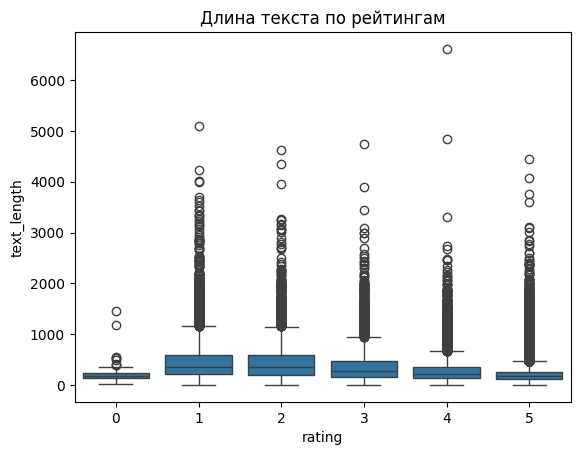

In [ ]:
# Наличие закономерности между оценкой и длиной текста
new_df['text_length'] = new_df['text'].str.len()
print('Статистика по длине текста:')
print(new_df['text_length'].describe())
print()

sns.boxplot(data=new_df, x='rating', y='text_length')
plt.title('Длина текста по рейтингам')
plt.show()

**Промежуточный вывод:** Анализ целевой переменной выявил сильный дисбаланс классов: подавляющее большинство отзывов (около 84%) имеют оценку 4 или 5, в то время как негативные оценки составляют не более 15%. Мы также проанализировали длину текстов и построили боксплоты: медианная длина комментария составляет 192 символа. Интересно, что самые длинные отзывы с большим количеством выбросов характерны для низких оценок, что в целом логично, т. к. люди склонны подробно описывать негативный опыт, а позитивный описывать в "трех словах, например", "Все понравилось", "Все было вкусно" и т. п.
Информация о дисбалансе классов и новый признак можно использовать при обучении моделей.

In [ ]:
# Средняя оценка по рубрикам
print(new_df.groupby('rubrics')['rating'].agg(['mean', 'count']).sort_values('count', ascending=False).head(10))

                                                                      mean  count
rubrics                                                                          
Ресторан                                                          4.511324  14615
Кафе                                                              4.403607  12366
Супермаркет                                                       4.398584   8899
Магазин продуктов                                                 4.403668   5289
Быстрое питание                                                   4.017340   4902
Ресторан;Кафе                                                     4.530303   4554
Супермаркет;Магазин продуктов                                     4.221757   4541
Кафе;Ресторан                                                     4.478059   3669
Магазин продуктов;Магазин хозтоваров и бытовой химии;Супермаркет  4.170179   2515
Кофейня                                                           4.590547   2137


In [ ]:
# Средняя оценка по названию места
print(new_df.groupby('name_ru')['rating'].agg(['mean', 'count']).sort_values('count', ascending=False).head(10))

                      mean  count
name_ru                          
Пятёрочка         4.431083   6029
Магнит            4.167824   2592
Красное&Белое     4.496536   1732
Вкусно — и точка  3.675699   1181
Перекрёсток       4.355321   1137
Леруа Мерлен      4.331834    889
Дикси             3.672355    879
Продукты          4.394286    875
Чижик             4.514208    739
Светофор          4.181818    715


In [ ]:
# Средняя оценка по адресу
new_df['city'] = new_df['address'].str.extract(r'(?:г\.|город)\s*([А-ЯЁ][а-яё-]+)', expand=False)
new_df['city'] = new_df['city'].fillna(new_df['address'].astype(str).str.split(',').str[0].str.strip())

print(new_df.groupby('city')['rating'].agg(['mean', 'count']).sort_values('count', ascending=False).head(10))

                           mean  count
city                                  
Москва                 4.371029  31763
Санкт-Петербург        4.447478  19011
Московская область     4.387293  14764
Краснодарский край     4.513117   9072
Республика Татарстан   4.483524   4279
Свердловская область   4.370784   3765
Нижний Новгород        4.453769   3277
Краснодар              4.493466   2908
Ленинградская область  4.341622   2775
Ростов-на-Дону         4.444218   2456


**Промежуточный вывод:** Больше всего комментариев относится к рубрикам "Ресторан" и "Кафе" (их средний рейтинг 4.4-4.5), далее - ритейл, где средняя оценка ниже. Среди брендов лидируют "Пятерочка" и "Магнит" по количеству отзывов. Мы также выделили города для понимания того, стоит ли включать этот признак при обучении: как итог, больше число комментриев оставлено для заведений и магазинов в Мск, МО и Спб.



In [ ]:
# Наличие текстов на английском
is_cyrillic = new_df['text'].str.contains('[а-яА-Я]', na=False)
non_cyrillic = new_df[~is_cyrillic]

print(f'Количество текстов на английском: {len(non_cyrillic)}')
print()
display(non_cyrillic[['text', 'rating']].style.set_properties(**{'text-align': 'left'}).set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

Количество текстов на английском: 2



,text,rating
38187,"A very beautiful and stylish place with a huge assortment of delicious dishes, I recommend trying sea urchins, marbled beef steak, scallops and oysters - excellent dishes, also special thanks to the chef for a very unusual presentation, kind and helpful staff, nice atmospheric music played, perfectly suitable for the interior of this institution, in the aggregate of all factors, a very pleasant and unique atmosphere is created in no other institution, I want to stay in this institution for a long time. I recommend everyone to visit this place. You'll like it",5
213844,The best cafe between Perm and Gubaha,4


In [ ]:
# Наличие комментариев без текста, с символами, цифрами и эмодзи
is_alpha = new_df['text'].str.contains('[a-zA-Zа-яА-Я]', na=True)
not_alpha = new_df[~is_alpha]
print(f'Количество текстов без букв: {len(not_alpha)}')

Количество текстов без букв: 0


In [ ]:
# Наличие упоминания рейтинга (цифры) в комментариях
new_df['num_count'] = new_df['text'].str.count(r'\d+')
print(new_df.groupby('rating')['num_count'].describe()[['mean', '50%', 'max']])

is_num = new_df['text'].str.contains(r'\d{4,}', na=False)
print()

# Наличие цифр и рейтинг
for rating in [0, 1, 2, 3, 4, 5]:
    subset = new_df[is_num & (new_df['rating'] == rating)]

    print(f'Рейтинг: {rating}')

    styled_df = (
        subset[['text', 'rating']]
        .head(1)
        .style
        .set_properties(**{'text-align': 'left'})
        .set_table_styles([{
            'selector': 'th',
            'props': [('text-align', 'left')]
        }])
        .set_properties(subset=['text'], **{'max-width': '600px', 'white-space': 'normal'})
    )
    display(styled_df)

    print()

            mean  50%   max
rating                     
0       0.191781  0.0   7.0
1       1.832306  1.0  66.0
2       1.491759  0.0  27.0
3       1.024575  0.0  25.0
4       0.576495  0.0  27.0
5       0.275320  0.0  28.0

Рейтинг: 0


,text,rating
379296,"Изначально, наша компания (6 человек), собирались ехать в сочи в отель Аквалоо, по прибытию, нами было принято решение (нас заселили в 9 корпус, который похож на общагу, плюс тараканы), что мы едем в Ригу в Крым (наши друзья там отдызали три гтда назад). Мы априехали в 3 часа еочи, на ресепшен наш дождался молодой человек, который мгновенно оформил документы, проводил нас в номера. Мы прлучили кучу положительных эмоций, просто не описать словами! Было видно, за что мы заплатили 80 тысяч рублей. Ешь и пей сколько хочешь и в любое время суток (кроме алкоголя, бар до 22.00) ,в номерах каждый день уборка, особенно стоит отметить услуги прачечной, ни сколько не пожалела, что отдала 1400 рублей за стирку, т. К. Эти услуги оплачиваются отдельно. Я уже хотела выкидывать носки ребенка после поезда, но после волшебной стирки в Риге, мне принесли их как будто новыми)) я удивлена была наповал) что касается анимации, конечно она на высшем уровне, интересно как и детям, так и взрослым) еда вообще шик, никогда столько не ела в день разнообразной пищи. Всем хочется выразить благодарность за отдых, если бы не Рига, он был бы испорчен) мы обязательно вернемся, это был лучший отдых😍💓😍",0



Рейтинг: 1


,text,rating
240,"Хорошая кафешка, можно недорого пообедать!\nВыдавальшицы еды(по другому их назвать не могу) не в курсе из чего приготовлен еда! 🤦‍♂️ ШЕФ, ОТЗОВИСЬ УЖЕ! \nПохоже, повара не в курсе, что крупу надо промыть перед варкой! В гречке постоянно чёрные, нерасшелушённые семена попадаются! Значит и с остальными крупами они обращаются так же - не промывают и не перебирают. Возможно ещё какие-то косяки на кухне есть, хз. Но вкусно и недорого, я люблю это место!))\nА ещё они не умеют сервировать квашеную капусту - не добавляют масло и лук!\nУчитывая всё вышеперечисленное, шеф здесь некомпетентен, мягко говоря. \nЕщё добавлю - подавая рассольник, берут ещё 15 рублей за ложку сметаны! 🤦‍♂️ Я считаю - сметана входит в рецепт, крохоборы, короче! \nНЕ РЕАГИРУЮТ НА КРИТИКУ!\nДополню- 24 июля 2023 ничего не изменилось, шеф как был ***, так и остался(((",1



Рейтинг: 2


,text,rating
94,"Кроме того, что место красивое и необычное, плюсов нет. Были 1 июня.\nАренда 2500 час, но это просто за иглу. 1000 пробковый сбор, хотя по умолчанию в заведении нет напитков и еды, все приносишь с собой. Сервировка стола платная, при этом сюда входит тарелка,стакан и приборы (Рюмка или бокал за отдельную плату). Посуда самая дешевая, при этом за 1 разбитую единицу штраф-1000. Стол в иглу, которое досталось нам был не закреплен. Т.е крышка и подножья стола существовали отдельно, каждый раз стол болтался, и не разбить там посуду было сложно. Музыкальная колонка тоже попалась «уставшая» громкость не регулировалась. Заказ был на 3 часа+ 1 в подарок, при этом девушка-администратор, насчитала за 4 часа. Прям настаивать пришлось, чтобы сделать перерасчет. Ощущение, что за все пытаются сбить деньги, при этом сервис на 2 балла.",2


... (2 outputs left out)


Рейтинг: 4


,text,rating
6,"Глубинка страны во всех своих проявлениях. Ассортимент столовский, интерьер, качество и цены приемлемые для средней бюджетной столовой СССР, не все чистое, все не новое... А что бы вы хотели на трассе. Поел, желудок не бастовал, значит риск был оправдан. Номер для ночлега аналогичного толка. Пластиковое окно нормально не закрылось, шторы на окне нет, только тюль. Для первого этажа - плохо. Мало ли кто заглядывает. Туалет, душ... Совок, но, повторюсь, для трассы да за 1000 руб - сойдет.",4



Рейтинг: 5


,text,rating
287,"Напитки в ассортименте. Пиво супер. Есть достойная альтернатива моему любимому Гиннессу. Персонал не подхалимничает, но достаточно приветлив. Ребраааа... Это восторг! Очень приличные колбаски. Гренки также хороши, крылышки... Из вин, мы брали Мальбек. Бутылка 2500. Атмосфера уютно-демократичная. Музыка живая... В общем провести время, посидеть, отдохнуть, послушать музыку и посмотреть футбол... Отличное место.",5


**Промежуточный вывод:** В рамках проверки гипотез об аномалиях мы проверили наличие неинформативных текстов, например:

*   было найдено всего 2 отзыва полностью на английском языке;
*   проверили наличие комментариев без букв - таких не оказалось;

Интересно было также посмотреть, как наличие числовых данных в комментариях отражается на рейтинге отзыва. Изначально это было сделано, чтобы посмотреть содержит ли отзыв рейтинг, и могут ли возникнуть риски из-за этого во время обучения (например, "Ваше заведение просто на 5 с плюсом!!" или "Ставлю вам 1! Это ужасное место"). Однако анализ использования цифр в тексте показал, что люди могут также писать о времени, количестве персонала, цене, дате или какое-то инфо о товарах.

In [ ]:
# Наличие оценок в каждой рубрике
pivot = pd.crosstab(new_df['rubrics'], new_df['rating'])
pivot['total'] = pivot.sum(axis=1)

# Поиск пропусков в оценках
ratings_cols = [1, 2, 3, 4, 5]
is_missing = (pivot[ratings_cols] == 0).any(axis=1)
missing_ratings = pivot[is_missing]

# Поиск кейсов с самыми низкими оценками
pivot['neg_comm_share'] = (pivot[1] + pivot[2]) / pivot['total']
popular_and_pos = pivot[pivot['total'] > 50]

In [ ]:
# Рубрики (самые популярные), где отсутствует хотя бы одна оценка
print(missing_ratings[['total', 1, 2, 3, 4, 5]].sort_values('total', ascending=False).head(10))

rating                                  total   1  2  3   4    5
rubrics                                                         
Кондитерская;Торты на заказ               135  10  0  4   6  115
Ресторан;Бар, паб;Суши-бар                118   4  1  0  12  101
Кафе;Кондитерская;Кейтеринг               102   4  0  9   6   83
Спортивное питание;Фитопродукция, БАДы     86   3  0  1   0   82
Столовая;Кафе;Банкетный зал                74   2  2  0   9   61
Кондитерская;Пекарня;Кафе                  69   7  0  3   6   53
Кондитерская;Магазин кулинарии             67  11  0  5   9   42
Кофе с собой;Кофейня                       64   1  1  2   0   60
Пиццерия;Суши-бар                          61   9  1  1   0   50
Мёд и продукты пчеловодства                58   1  0  0   2   55


In [ ]:
# Рубрики без низких оценок
print(popular_and_pos[['total', 'neg_comm_share']].sort_values('neg_comm_share').head(10))

rating                                                   total  neg_comm_share
rubrics                                                                       
Бар, паб;Ночной клуб;Кальян-бар                            293        0.013652
Мёд и продукты пчеловодства                                 58        0.017241
Супермаркет;Магазин продуктов;Продуктовый гипермаркет       58        0.017241
Кафе;Бар, паб;Кальян-бар                                    57        0.017544
Ресторан;Суши-бар;Банкетный зал                             53        0.018868
Магазин чая;Магазин подарков и сувениров;Магазин кофе       51        0.019608
Магазин продуктов;Магазин мяса, колбас;Молочный магазин     97        0.020619
Ресторан;Быстрое питание;Доставка еды и обедов             268        0.022388
Магазин чая                                                 86        0.023256
Рынок;Продуктовый рынок;Вещевой рынок                      104        0.028846


**Промежуточный вывод:** В целом мы видим, что есть категории, в которых вовсе отсутствует рейтинг с какой-либо цифрой. Эта информация интересна с той точки зрения, что могут быть рубрики с двумя "полярностями", например, в ней рейтинг равен либо 1, либо 5, иного не дано.

Отсюда следует вопрос: а каких комментариев больше? В целом первого вывода достаточно, чтобы ответить на этот вопрос, но бизнес зачастую интересуется объемом негативных комментариев, поэтому второй вывод показывает это самое распределение. Интересный факт: самый низкий объем негативных комментариев у рубрики "Бар, паб;Ночной клуб;Кальян-бар". Возможно, в это тоже заложен какой-то смысл.

### **Семантический анализ и поиск слов-маркеров**

**Описание**: Важно изучать тексты не только с точки зрения базовой статистики, но и с точки зрения семантики текста. Семантику текста не всегда можно посчитать явным образом, но она может быть тесно взаимосвязана с анализируемыми признаками.

In [ ]:
# Поиск наиболее частых слов/словосочетаний в комментариях с разным рейтингом
def ngrams(text, n, k=5):
  vec = CountVectorizer(ngram_range=(n, n), stop_words=russian_stop_words, min_df=5)
  X = vec.fit_transform(text)
  sums = X.sum(axis=0).A1
  frequency = sorted(zip(vec.get_feature_names_out(), sums), key=lambda x: -x[1])[:k]
  return frequency

for num in [0, 1, 2, 3, 4, 5]:
  text = new_df[new_df['rating'] == num]['text']
  print(f'Униграммы рейтинга {num}:')
  for word, cnt in ngrams(text, n=1):
    print(f'{word}: {cnt}')
  print()

for num in [0, 1, 2, 3, 4, 5]:
  text = new_df[new_df['rating'] == num]['text']
  print(f'Биграммы рейтинга {num}:')
  for word, cnt in ngrams(text, n=2):
    print(f'{word}: {cnt}')
  print()

Униграммы рейтинга 0:
очень: 42
вкусно: 18
всё: 17
персонал: 15
это: 13

Униграммы рейтинга 1:
это: 6280
очень: 3889
заказ: 2895
просто: 2844
минут: 2379

Униграммы рейтинга 2:
это: 2856
очень: 2545
просто: 1125
минут: 912
меню: 817

Униграммы рейтинга 3:
очень: 4710
это: 3682
просто: 1339
цены: 1316
персонал: 1313

Униграммы рейтинга 4:
очень: 8407
это: 4306
персонал: 3036
цены: 2789
вкусно: 2782

Униграммы рейтинга 5:
очень: 82098
персонал: 30387
вкусно: 29649
место: 26947
это: 20443

Биграммы рейтинга 0:
высшем уровне: 5

Биграммы рейтинга 1:
данное заведение: 466
это заведение: 346
20 минут: 307
это место: 289
40 минут: 280

Биграммы рейтинга 2:
желать лучшего: 132
данное заведение: 129
это место: 122
это заведение: 119
очень долго: 117

Биграммы рейтинга 3:
еда вкусная: 204
желать лучшего: 181
очень вкусно: 180
очень долго: 163
оставляет желать: 154

Биграммы рейтинга 4:
большой выбор: 500
очень вкусно: 468
хороший магазин: 459
еда вкусная: 362
персонал вежливый: 352

Биграммы рей

**Промежуточный вывод:** Униграммы и биграммы - это достаточно простой, но интересный инструмент для данного анализа: он показывает нам, есть ли какие-нибудь достаточно типичные слова, которые описывают конкретный рейтинг. Для этого посмотрим на биграммы, они более наглядны: для оценок выше 4-ки мы видим фразы "очень вкусно", "большой выбор", "вежливый персонал", "еда вкусная"  и т. п., а вот уже рейтинг, с оценкой 3 и ниже, содержит в себе такие слова, как "оставляет желать лучшего", "очень долго", "это место/заведение", а также указание на потраченное время, деньги и работу персонала. Более того, для обучения целесообразно использовать оценки выше 0: их мало, и они неинформативные, если смотреть на биграммы (странно, что 0 стоит на комментарии с "высшем уровне: 5", это больше вопрос о качестве данных).

In [ ]:
# Определение семантики текста
rubert = pipeline("sentiment-analysis", model="blanchefort/rubert-base-cased-sentiment", truncation=True, max_length=256, device=0)
unique_texts = new_df['text'].unique().tolist()
batch_size = 64

results = []
for i in tqdm(range(0, len(unique_texts), batch_size), desc='Определение тональности'):
  batch = unique_texts[i:i+batch_size]
  results.extend(rubert(batch))

mapping = {'POSITIVE': 1, 'NEGATIVE': -1, 'NEUTRAL': 0}
sentiment_map = {}
for text, res in zip(unique_texts, results):
  sentiment_map[text] = mapping.get(res['label'], 0) * res['score']

config.json:   0%|          | 0.00/943 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/499 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Определение тональности:   0%|          | 0/2554 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


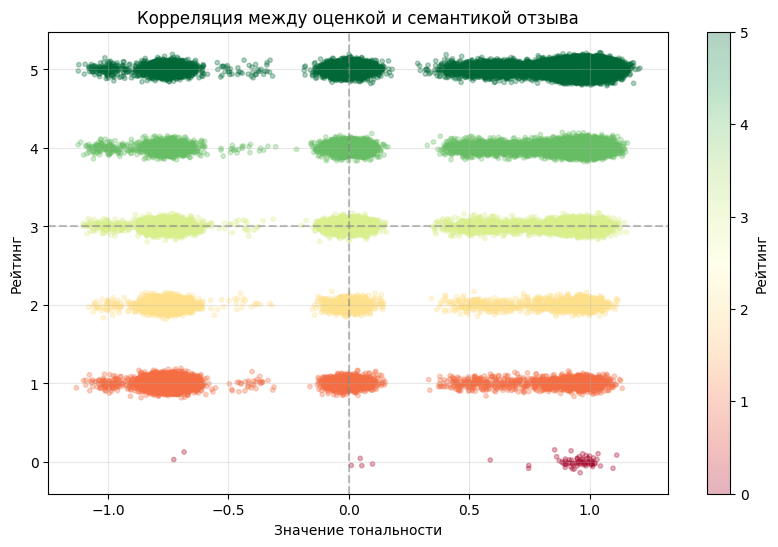

In [ ]:
# Зависимость между оценкой и тональностью комментария
new_df['sentiment'] = new_df['text'].map(sentiment_map).fillna(0)

x = new_df['sentiment'] + np.random.normal(0, 0.05, len(new_df))
y = new_df['rating'] + np.random.normal(0, 0.05, len(new_df))

plt.figure(figsize=(10, 6))
scatter = plt.scatter(x, y, c=new_df['rating'], cmap='RdYlGn', alpha=0.3, s=10)
plt.axhline(y=3, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
plt.xlabel('Значение тональности')
plt.ylabel('Рейтинг')
plt.title('Корреляция между оценкой и семантикой отзыва')
plt.colorbar(scatter, label='Рейтинг')
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# # Определение границ тональности
# percentiles = []

# for p in range(1, 100):
#     q = p / 100
#     val = new_df['sentiment'].quantile(q)

#     count = len(new_df[new_df['sentiment'] <= val])
#     percentiles.append({
#         'Процентиль': f'{p}%',
#         'Значение тональности': round(val, 4),
#         'Кумулятивное число строк': count})

# df_percentiles = pd.DataFrame(percentiles)
# print(df_percentiles.to_string(index=False))

In [ ]:
# Расхождение между оценкой и семантикой текста
anomaly_neg_high = new_df[(new_df['sentiment'] < -0.7) & (new_df['rating'] >= 4)]
anomaly_pos_low = new_df[(new_df['sentiment'] > 0.4) & (new_df['rating'] <= 2)]

print(f'Негативный текст с высоким рейтингом: {len(anomaly_neg_high)} ({len(anomaly_neg_high)/len(new_df):.2%})')
print(f'Позитивный текст с низким рейтингом: {len(anomaly_pos_low)} ({len(anomaly_pos_low)/len(new_df):.2%})')

Негативный текст с высоким рейтингом: 4208 (2.57%)
Позитивный текст с низким рейтингом: 2673 (1.64%)


In [ ]:
# Примерв таких кейсов
anomalies_total = [('Негативный текст с высоким рейтингом', anomaly_neg_high),
                      ('Позитивный текст с низким рейтингом', anomaly_pos_low)
]

for title, df_anomaly in anomalies_total:
    styled_anomaly = (
        df_anomaly[['text', 'rating', 'sentiment']]
        .tail(3)
        .style
        .set_properties(**{'text-align': 'left'})
        .set_table_styles([{
            'selector': 'th',
            'props': [('text-align', 'left')]
        }])
        .set_properties(subset=['text'], **{'max-width': '800px', 'white-space': 'normal'})
    )

    display(styled_anomaly)

,text,rating,sentiment
499608,"Не знаю как квас, но вот когда идёшь мимо СТАРОМИНСКОГО кваса по Краснощербиновской жалеешь людей которые рядом живут. Иногда запах отвратительный - брожения или что там ещё.",5,-0.751653
499792,"Все всегда очень вкусно. И быстро. Одно из самых любимых мест в городе. НО!! Были очень огорчены атмосферой и качеством обслуживания в СуперТяж на Хрюкина. На столах салфеток НЕТ!! Элементарно положить грязную палочку от кофе не куда... Во время заказа несколько раз сказали что ""будем кушать здесь"" . Итог: заказ сделали как с собой, а на вопрос что мы заказывали здесь, ответили что у них нет подносов. \nЕли как могли.. Да мы не хрюши, но лучше ведь когда капает на поднос , и когда грязные салфетки на подносе, а не на столе.. \nУ мужа шаурма вытекла в пакет... А мой хот-дог Нью-Йорк (который я попросила сделать без лука) они плюсом ЗАЛИЛИ соусами двойной порцией... Зачем?? Я просила? Нет! Выковыривала и счищала всю эту кашу кофейной палочкой.... Еще и сосиска вся сморщенная, будто не свежая.... \nОчень огорчены, и именно в этом заведении больше не будем посещать вас, и рекомендовать тоже не будем... Стыдно.\nА ведь вы лучшие",4,-0.751441
499812,"Вкусная пицца! Но снимаю звезду , тесто по краям подгорелое.такую пиццу не выносят в зал это брак",4,-0.751660


,text,rating,sentiment
498995,"Помещение хорошее уютное, почти каждую неделю бываю в этой пиццерии.Заказы выдают быстро без задержек. Но ставлю такую оценку только из-за одного , из-за кофе. Ни когда не покупал тут кофе, и решил взять попробовать. Взял большой стаканчик 400мл капучинно. Так вот в этих 400мл кофе всего где-то наполовину налито и то если не меньше остальное одна пена. И стоит оно 150 рублей. В других местах кофе стоит дешевле и по объёму больше. Больше ни когда не буду брать тут кофе.",1,0.958378
499487,"Были не так давно в данном заведении и если честно не в восторге. Кухня на ""3"", музыка на твёрдую ""4"". Надо отдать должное, обслуживание очень хорошее. Ещё один минус, но это лично для меня, нельзя расплатиться картой, либо наличными, либо перевод, что не удобно. Ещё раз туда я не пойду. Да и Жирный плюс для многих это свой алкоголь. Для меня это не плюс, т.к нужно было обязательно взять на 1500 т. с человека. А когда вас три девушки, там обожар....ся просто. Для юбилеев это конечно огромный плюс, свой алкоголь.",2,0.952970
499625,"Приятно посещать,замечательное обслуживание,вежливые продавцы. Продукция всегда свежая, напитки холодные. Классный магазин!!!",1,0.980650


**Промежуточный вывод:** Для семантического анализа воспользуемся предобученной языковой моделью RuBERT от blanchefort, которая специализируется на анализе тональности текстов на русском. Однако код, предложенный автором, выдает только класс тональности (0: NEUTRAL, 1: POSITIVE, 2: NEGATIVE), а представленный - сразу переводит предсказания в непрерывную шкалу от -1 до 1 с учетом уверенности модели, обозначаемая как `score`.

Результаты обучения были изображены на графике, и как можно увидеть - среди положительных оценок есть негативные по тональности комментарии, и наоборот - для отрицательных комментариев. Это необязательно может быть аномалия, есть вероятность, что модель могла посчитать какие-то конкретные слова супер негативными/позитивными, какими они не являются. Или же человек не слишком лояльно/строго оценил место, несмотря на свой комментарий. Чтобы убедиться в этом мы посмотрели пару примеров таких текстов. Частично, так и вышло, например, `499792` и `499812`: тексты с наличием критики моделью расцениваются также как негативные, хотя это может быть просто замечание клиента, не влияющее сильно на оценку (наша модель вышла уж чересчур чувствительной). А есть и явные аномалии: строка с индексом `499608` имеет сильно негативный окрас, но покупатель оценил место на 5.

В общем и целом, глядя на такие примеры, мы можем сказать, что потенциальными аномалиями в нашем обучении можно считать комментарии под индексами `499608` и `499625`. Именно такие случаи наша модель должна будет выявлять.

In [ ]:
# Скачивание словаря
url = 'https://raw.githubusercontent.com/dkulagin/kartaslov/master/dataset/kartaslovsent/kartaslovsent.csv'
kartaslov = pd.read_csv(url, sep=';')
kartaslov.head()

,term,tag,value,pstv,ngtv,neut,dunno,pstvNgtvDisagreementRatio
0,абажур,NEUT,0.08,0.185,0.037,0.580,0.198,0.00
1,аббатство,NEUT,0.10,0.192,0.038,0.578,0.192,0.00
2,аббревиатура,NEUT,0.08,0.196,0.000,0.630,0.174,0.00
3,абзац,NEUT,0.00,0.137,0.000,0.706,0.157,0.00
4,абиссинец,NEUT,0.28,0.151,0.113,0.245,0.491,0.19


In [ ]:
# Тексты с критикой и похвалой одновременно
sentiment_dict = dict(zip(kartaslov['term'], kartaslov['value']))

new_df['words'] = new_df['text'].str.lower().str.split()
pos = new_df['words'].map(lambda words: any(sentiment_dict.get(w, 0) > 0.5 for w in words))
neg = new_df['words'].map(lambda words: any(sentiment_dict.get(w, 0) < -0.7 for w in words))

mixed_texts = new_df[pos & neg]
new_df.drop(columns=['words'], inplace=True)

print(f'Доля текстов со смешанной стилистикой: {len(mixed_texts)} ({len(mixed_texts)/len(new_df):.2%})')
print()

print('Распределение рейтингов:')
print(mixed_texts['rating'].value_counts().sort_index())
print()

print('Примеры:')
styled_mixed = (
    mixed_texts[['text', 'rating']]
    .sample(min(5, len(mixed_texts)))
    .style
    .set_properties(**{'text-align': 'left'})
    .set_table_styles([{
        'selector': 'th',
        'props': [('text-align', 'left')]
    }])
    .set_properties(subset=['text'], **{'max-width': '800px', 'white-space': 'normal'})
)
display(styled_mixed)

Доля текстов со смешанной стилистикой: 7724 (4.72%)

Распределение рейтингов:
rating
0       3
1    2296
2     879
3    1036
4    1088
5    2422
Name: count, dtype: int64

Примеры:


,text,rating
100218,"Уважаемые посетители кафе, а так же те, кто основывается на необоснованных отзывах других людей, попробуйте подумать своей головой! Маски - это неотъемлемая часть эпидемиологической обстановки во всей стране, эти правила придумывают явно не сотрудники ЛЮБОГО заведения общественного питания, выражать недовольство здесь глупо. Очевидно, что в заведении нельзя есть свою еду и пить свои напитки, вы же в кино со своим фильмом не ходите?…\nЯ хожу туда не первый год и это одно из лучших мест в Москве! Отличная команда, дружелюбные ребята и самое главное еда и обслуживание на высшем уровне! А те кто пишет необоснованные гневные отзывы, задумайтесь, может у вас ума как у ракушки? \nИ еще раз всем сотрудникам кафе Трапезная огромное СПАСИБО за Ваш труд и терпение! Вы лучшие ❤️❤️❤️",5
75612,"Хочу выразить свое восхищение вашими роллами. \nДоставка всегда даже меньше часа, никогда не опаздывают.\nКачество роллов идеальное. К тому же у меня сильная аллергия на несвежие креветки, всегда боюсь заказывать их в каких либо заведениях, но я рискнула и ни разу не пожалела. Вкусно, быстро, и никаких проявлений аллергии.",5
209488,"Персонал 50/50,ктото вежливый и отзывчивый, а кто-то злой и грубый, выбор товара средний. Сказать что чистый, Не-а не чистый начиная от пола и заканчивая прилавками. Расположение нормальное, не удобно заезжать на машине. Скидки есть по факту, а на деле вернее на ценнике нет. Фрукты и овощи нужно перебирать, а то они тухнет от этого и мошки. Кассы чистые один минус в акций постоянно какой то бардак",2
14755,"5 звёзд авансом.\nОтзыв как обратная связь без негатива!\nМаста мало и в целом душно ,низкое качество соединения.\nПришел сюда с товарищем он из другой страны приехал провелать родину! хотели бодро провести время как в старые добрые ,по итогу так себе(.\nПо оборудованию - в осном зале все самое обычное ,наушники без нормального звучания ,клавиатура одна из самых дешёвых ,но для игр достаточно.\nМониторы порадовали - хорошая картинка и цвета натуральные.\nПо железу каждому свое ,но имея 6900 под боком чувствуешь дискомфорт ,но друг конечно не заметил ничего такого.\nВ целом это просто обратная связь и место рекомендую к посещению,владельцы ответственные люди и реагируют на все ,поэтому ваши замечания делают геймниндустрию только лучше.\nЯ очень рад что такие места открываются и развиваются.\nБез негатива ,было здорово ,но моменты я указал.\n",5
366583,"Сегодня были в данном заведении, заказали мидии, в честь технического открытия угостили белым вином. После посещения все понравилось, приветливый персонал, вкусная еда, если бы не одно НО, по приезде домой моему молодому человеку стало плохо!!! Отравление на лицо, весь вечер тошнота, рвота, температура. После ничего больше не ели, так как уже через три часа чувствовал себя не очень. Вопрос, за что заплатили? Чтобы весь вечер + ночь корчиться? Очень разочарованы, выходные испорчены!!!",1


**Промежуточные выводы:** Для проведения более тонкого лингвистического анализа мы загрузили открытый словарь тональности русского языка "Картаслов". Этот подход полезен с той стороны, что RuBERT смотрит на текст целиком и определяет его характер, а словарь позволит нам заглянуть внутрь предложений и найти конкретные слова-маркеры (мы пытались ранее выявлять такие слова-маркеры, но теперь мы это делаем не на основе частоты встречаемости таких слов, а именно на наличии таких слов в целом).

Это все нужно, чтобы как раз-таки найти те самые предложения, где, грубо говоря, есть и комплимент, и похвала (наш RuBERT спотыкался на таких примерах и неверно определял их тональность). Итого, таких примеров в нашем датасете около 5% с учетом наших границ (для плохих слов граница подбиралась выше, чтобы алгоритм был менее "обидчивым" и воспринимал негативными только супер обидные слова). Как итог, последние 3 предложения действительно соответствует заданной логике, а вот в первых двух случаях - исключение, алгоритм неидеален.

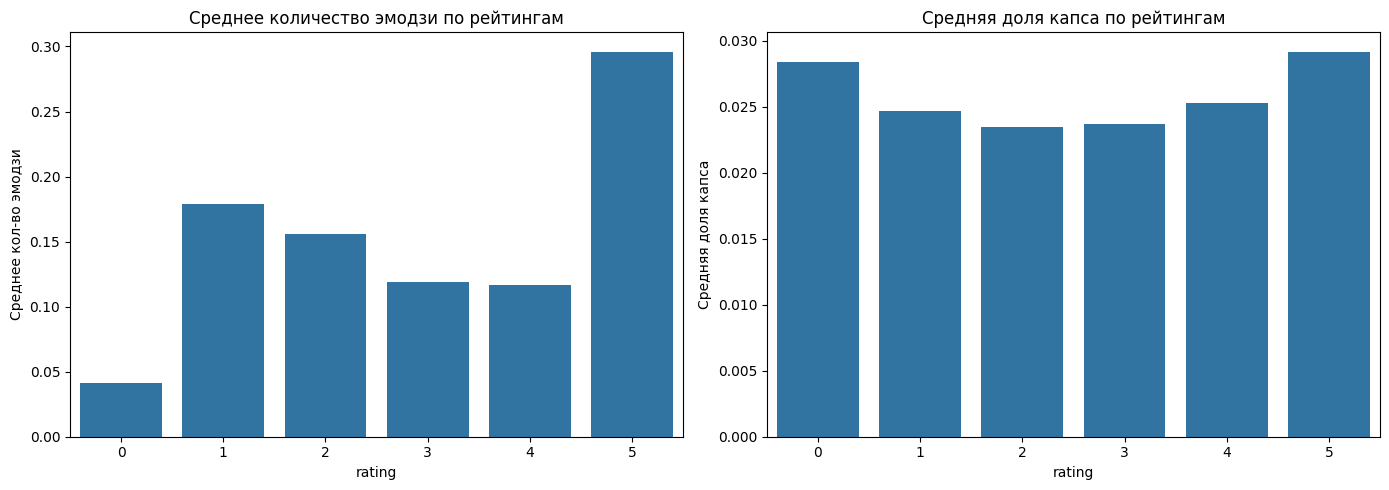

In [ ]:
# Использование капса и эмоджи - отражение тональности текста
new_df['emoji_count'] = new_df['text'].apply(lambda t: len(emoji.emoji_list(t)))
new_df['caps_ratio'] = new_df['text'].apply(lambda t: (sum(c.isupper() for c in t if c.isalpha()) / sum(c.isalpha() for c in t)if any(c.isalpha() for c in t) else 0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=new_df, x='rating', y='emoji_count', ax=axes[0], errorbar=None)
axes[0].set_title('Среднее количество эмодзи по рейтингам')
axes[0].set_ylabel('Среднее кол-во эмодзи')

sns.barplot(data=new_df, x='rating', y='caps_ratio', ax=axes[1], errorbar=None)
axes[1].set_title('Средняя доля капса по рейтингам')
axes[1].set_ylabel('Средняя доля капса')

plt.tight_layout()
plt.show()

In [ ]:
# Несоответствие положительной оценки с негативным эмоджи
angry_emoji = ['😡', '🤬', '😠', '👎', '🤮', '💩']
angry_but_pos = new_df[new_df['text'].apply(lambda t: any(e in t for e in angry_emoji)) & (new_df['rating'] == 5)]

print(f'Количество положительных рейтингов с негативным эмоджи: {len(angry_but_pos)}')
print()

print('Примеры:')
styled_angry = (
    angry_but_pos[['text', 'rating']]
    .head(5)
    .style
    .set_properties(**{'text-align': 'left'})
    .set_table_styles([{
        'selector': 'th',
        'props': [('text-align', 'left')]
    }])
    .set_properties(subset=['text'], **{'max-width': '800px', 'white-space': 'normal'})
)

display(styled_angry)

Количество положительных рейтингов с негативным эмоджи: 17

Примеры:


,text,rating
9634,"Решили с друзьями культурно провести вечер.\nКое как нашли вход , внутри было крайне мало места! (Это важно, у одного из моих товарищей клаустрофобия)\nРешили расположиться на одном из уличных столиков , что было явной ошибкой...\n2 Раза пристал какой то бомжара, клянчил деньги, забрал у меня 100руб.\nВ общем - ужасно 😡",5
26912,"Расположение удобное, но со стороны парковки просто беда, все заставлено, пройдти к магазину и ж/д вокзалу это квест😂. В магаз. Всегда очереди на кассу, потому что работают не все кассы, то они товар выкладывают, то они обед. Так частенько, выбор товара присутствует, овощи всегда свежие. Персонал грубый, не все, но есть личности. А ещё очень пахнет чебуреками и беляшами, выходишь из магазина и от тебя такой шлейф всего этого😷🤮 ужасно, поэтому я туда захожу очень редко.",5
36841,"еда вкусная, готовят заказы быстрее, чем когда был макдональс, персонал крутой, бургеры очень вкусные, каждый день бы ела, но дороже на 10 рублей, чем раньше 😡 напитки вкусные, но дорогие, как и соусы. 😭 все чисто, кофе не пью, мясо нормальное, атмосфера нормальная, правда бесят нефоры которые подсаживаются🆘 кароче класс все",5
62630,"Посетил данный бар первый раз и скажу вам открыто это ОЧЕНЬ ХОРОШЕЕ МЕСТО!\nПиво вкусное шоты так же хороши)\nДевушка сказала что ей очень сильно понравились роллы в нашем случае ""гейша"" ( вроде так называются 😅) \n\nМесто атмосферное тут вам и бильярд и большой настольный футбол.\nСвой вечер вы проведёте очень хорошо это я вам гарантирую!\n\nЦены на алко конечно кусаются за 0.5 венгерского и чешского пива 280 и 240 рублей соответственно)\nЛично я не попробовал только последние две позиции чешского организм сказал ""человек остановись""🤬\n\nНо минус один очень тихо играет музыка но может для кого-то это и плюс можно спокойно без криков общаться.\nТак что добавить 20% к музыке и будет вообще замечательно!\nНо это и не критично поэтому смело 5из5",5
147436,"Меняю отзыв на положительный. Да, и такое бывает.\nВ магазине первым делом заделали дыру в полу при входе и позже наконец-то положили нескользящие коврики! Теперь заходя в здание можно не бояться навернутся и получить травму, особенно в зимнее время. Благодарю!\n\n///Положите, наконец, резиновые коврики в магазине перед входом! Пол ОЧЕНЬ скользкий! Падать на каменную плитку невероятно больно! Повредила недавно вылеченую руку, сейчас опять прохожу лечение. Чудом не разбила телефон при падении! 🤬\nСам магазин нормальный, допустимые цены, есть что выбрать.\nP.s./\nНичего не изменилось. Наледь. Люди подскальзываются. В самом магазине появилась дыра в полу, будьте крайне аккуратны.",5


**Промежуточные итоги:** Несоотвествие эмоджи и оценки тоже может расцениваться как некоторая аномалия. Конечно, мы не можем привести весь полный список "злых" и "недовольных" эмоджи, но мы можем попытаться найти такие кейсы. Это такой маркер, где классический текстовый анализ бесполезен.

По этой причине для начала мы посмотрели на распределении эмоджи по разным рейтингам, а также по количеству символов, написанных капсом. И по графикам можно заметить, что в основном большое количество графиков используется в комментариях с рейтингом 5, текст капсом - аналогично. Второй по убыванию - это комментарии с рейтингом 1. Видимо, они одинаково популярны и там, и там, чтобы показать либо большое восхищение, либо большое разочарование.

Наконец, про несоответствия: их очень мало на весь объем данных - 17 кейсов (опять-таки количество может варьироваться в зависимости от выбранных смайликов), но они тоже имеют место быть.

In [ ]:
# Поиск текстов, короче 10 символов, по каждому рейтингу
# short_texts = new_df[(new_df['text_length'] < 44.0) & (new_df['rating'].isin([0, 1, 2, 3, 4, 5]))]
short_texts = new_df[(new_df['text_length'] < 20) & (new_df['rating'].isin([0, 1, 2, 3, 4, 5]))]

print(f'Доля коротких текстов: {len(short_texts)} ({len(short_texts)/len(new_df):.2%})')
print()
print('Распределение рейтингов:')
print(short_texts['rating'].value_counts())
print()
print('Примеры:')
for rating in sorted(short_texts['rating'].unique()):
    print(f'Рейтинг: {rating}')
    group = short_texts[short_texts['rating'] == rating]
    print(group.sample(min(5, len(group)))[['text']].to_string(header=False))
    print()

Доля коротких текстов: 283 (0.17%)

Распределение рейтингов:
rating
5    230
4     34
3     10
1      6
2      3
Name: count, dtype: int64

Примеры:
Рейтинг: 1
290376  товары хуже не куда
393421        Меню древнее.
314568            Не вкусно
487274     Очень дорого все
458755   Достойный магазин.

Рейтинг: 2
220510   Продавщица плохая
374254  Не вкусно. Долго. 
184363       Очень дорогой

Рейтинг: 3
330650  Неплохое место!!!
157904      Очень дорого!
121267       Очень тесно.
361693  Грубый контингент
365655  Очень мало места.

Рейтинг: 4
308657  Хорошее заведение 
77619   Ассортимент товара
196692  Вкусно и не дорого
494651  Хожу редко но норм
222490    Хороший магазин.

Рейтинг: 5
380473             Отлично.
194070  Круто, если коротко
189428   Любимый ресторан) 
405912    Интерьер, кухня\n
192855      Хорошая шаурма.



**Промежуточные выводы:** Можно также поизучать короткие, но информативные тексты по рейтингам и посмотреть опять-таки на некоторые слова маркеры, служащие некоторым идентификатором для оценки отзыва.

In [ ]:
# Поиск саркастичных комментариев
sarcasm_markers = ['ну спасибо', 'ну да ']
neg_words = kartaslov[(kartaslov['tag'] == 'NGTV') & (kartaslov['ngtv'] >= 0.549)]['term'].tolist() # <- медиана по колонке kartaslov['ngtv']

new_df['is_sarcastic'] = new_df['text'].apply(
    lambda t: (
        any(w in str(t).lower() for w in sarcasm_markers)
        and
        (
            any(w[:6] in str(t).lower() for w in neg_words)
            or
            any(q in str(t) for q in ['"', '«', '»'])
            or
            ('...' in str(t) or '…' in str(t))
        )
    )
)

only_sarcastic_texts = new_df[new_df['is_sarcastic'] == True]

In [ ]:
# Вывод саркастичных комментариев
print(f'Всего саркастичных текстов: {len(only_sarcastic_texts)} ({len(only_sarcastic_texts)/len(new_df):.2%})')
print()

print('Распределение рейтингов:')
print(only_sarcastic_texts['rating'].value_counts().sort_index())
print()

print('Примеры:')
for rating_val in [1, 2, 3]:
    print(f'Рейтинг: {rating_val}')

    anomaly_sarcasm = only_sarcastic_texts[only_sarcastic_texts['rating'] == rating_val]

    styled_sarcasm = (
        anomaly_sarcasm[['text', 'rating', 'sentiment']]
        .head(2)
        .style
        .set_properties(**{'text-align': 'left'})
        .set_table_styles([{
            'selector': 'th',
            'props': [('text-align', 'left')]
        }])
        .set_properties(subset=['text'], **{'max-width': '800px', 'white-space': 'normal'})
    )

    display(styled_sarcasm)

Всего саркастичных текстов: 78 (0.05%)

Распределение рейтингов:
rating
1    31
2    14
3     9
4     6
5    18
Name: count, dtype: int64

Примеры:
Рейтинг: 1


,text,rating,sentiment
18828,"Заказывал столик на 4х у вас. Посадили на второй этаж под кондиционер. Стол был мокрый,ну да ладно , сам протерли. Спустя некоторое время с него начала капать вода , а после и вообще полилась. Работника ресторана попросили выключить его -выключили, на просьбу пересадить в другое место - отказали хотя половина столов была свободна в зале. Через 15 минут кто то включил его на полную и вот тогда полился водопад, вещи промокли , коктейли испортились. Минуты 2 точно с него текло пока его не выключили , но место по итогу нашлось . Смешная конечно ситуация, но было не до смеха , вечер был испорчен",1,-0.751480
24487,"В конце прошлого года переехала в соседний дом. Поскольку поблизости нет полноценных супемаркетов, стала заглядывать в этот магазин. По началу ничего меня не смущало, но постепенно мне стали понятны некоторые особенности в работе этого магазина, которые не могут не возмутить. Вот правда, просто слов не хватает... Некоторые продавцы либо очень плохо изъясняются на русском языке, некоторые вдобавок еще и общаются по хамски! Торгуют как попало! Чеков зачастую не выдают! Постоянно просят оплатить переводом на карту Сбера. Ну очевидно ведь, что занимаются обманом. Цены выставляют каждый раз так как им вздумается, на полках бывает просроченный или испорченный товар, и все это - цветочки... Вокруг магазина снуют постоянно крысы, видела их раза 3, особенно когда идешь сзади магазина, видно как побежала и залезла под здание магазина. Вероятно от того и бродит по магазину серый кот, чтоб тех отпугивать или отлавливать. Не знаю. Хотя, лично мне, это тоже неприятно с учетом того, что в магазине продается выпечка, фрукты, овощи и все это открыто хранится... Как представлю, что с этим фруктами и булками могут делать эти ""животные"" просто тошнит от мысли, что я там когда-то что-то покупала. \nКроме того, каким-то странным образом ведется торговля алкоголем. Знаю от соседей, что покупают там спиртное. Видела как люди выходили оттуда с пивом. Сама спрашивала - мне ответили, что пива в продаже нет. Как-то, стоя в очереди, видела, как продавец вынес пиво со склада и передал покупателю. Спрашиваю - так пиво все таки есть в продаже? Отвечают - нет, это человек просто своё забирает. А деньги говорю за что тогда отдал он вам? Это за другое - отвечает. Потом узнала, что оказывается продажа пива и сигарет не приветствуется администрацией общежития, поскольку магазин находится на территории общежития для студентов. Потому эти предприимчивые торговцы ведут скрытую продажу алкоголя ""для своих"". Сигареты продаются там вполне открыто, я постоянно там их покупала. А для покупки пива я не заработала статус ""своего"" клиента.\nВ общем, просто КАРАУЛ!!! Куда смотрят проверяющие органы? Почему администрация общежития не замечает этого беспредела? \nМне не понятно... Хотя такую картину можно наблюдать во многих магазинах, где ведут торговлю выходцы из Кавказа и Азии. Видимо за это стоит нам благодарить наших не менее предприимчивых представителей тех самых проверяющих органов. \nВот специально зарегистрировалась, для того, чтоб оставить отзыв. Хотя обнаружила, что многие этот магазин хвалят и их вероятно все эти обстоятельства не смущают... \nМне сложно понять как такое возможно, с учетом всего, что я успела в нем увидеть за недолгое время моего проживания в этом районе. Либо этого никто не замечает, либо многих все это нисколько не смущает. Ну да ладно! Мой отзыв для других людей!",1,-0.751446


Рейтинг: 2


,text,rating,sentiment
29958,"Кофе ждал 15 минут, бургер больше 20. Бургер вкусный, кофе обычный. Можно быть порасторопнее, тем более что это мойка и люди не рассиживаться заходят. Формат такой есть: закусочная на заправке, Мойке, автосервисе. Не слышали?\nНе хотели быть закусочной))) это как? К вам люди не специально приезжают, а заходят делая дела: помыться, масло поменять, резину. Либо в шаровню, либо к вам))) даже по отзывам видно))) ну да ладно, не вы там первые, не вы последние судя по всему))) кстати, товарищ заезжал на мойку и к вам зашёл (вот совпадение, да?) и вы ему тоже несчастный бургер готовили дольше, чем мыли машину. Видите, в голове у клиента вы именно так и проходите: не тратить на вас больше времени, чем основное событие) я там часто шары катаю, наблюдаю за вами, чай 8 лет рестораны открывал)))",2,-0.751457
46145,"Пару человек советовали это заведение. Решил заказать доставку. Взял шашлык баранина, свинина и хинкали. Полтора часа ожидания. Привезли всё холодное,ну да ладно. Баранину жирную недожарили. Свинина норм. А вот хинкали-одни специи, невозможно есть. Жареный сулгуни так себе из-за жирнющей посыпки. В общем не буду там больше питаться.",2,-0.751450


Рейтинг: 3


,text,rating,sentiment
39214,"Ну что же СушкинСын слушай объективную историю что добавить и что поменять. Супруга на днях сказала что есть новое место в Тольятти с твоей любимой паназиатской кухней и вроде хотели заехать вместе но получилось так что товарищи отговорили от совместного похода и тестить пришлось со своим другом, для читателя поясню что мы с ним не один десяток лет уже тестим все заведения нашего города. Обслуживание конечно в этот день было немного усталое ну или не приглянулись мы с первого взгляда официантке, потому что элементарную улыбку и доброжелательности мы не увидели. Соглашусь и с другими отзывами что за обслуживанием приходилось бегать вплоть до того что бы закрыть счёт, в ином случае оставили бы на двоих не 7000 а в два раза больше (сейчас думаю об этом и даже отношу это в плюс 😁 так как спасибо за то что не даёте возможности порыву души развернуться и сделать лишних расходов) Ну да ладно об обслуживании перейдём к интерьеру, тут вроде на твёрдую четверку в сегменте паназиатской кухни, простыми словами и уютно и вроде чего то не хватает, хотя вся мебель вроде свежая, но тут как говориться ещё есть к чему стремится. Так вот, самое главное ради чего мы все это читаем)), кухня, тут объективно конечно может не получиться так как попробовали не все блюда из меню (динамит, том ям, курица в панировке, креветки в темпуре, салат с угрем и салат с телятиной) но в целом съедобно, том ям конечно не как в васаби в лучшие годы ( Самарский) но и сказать что не получился у них не могу, с рисом давольно не плохо залетает, да и динамит, конечно пробовал и лучше но и сказать что не вкусно не могу, так же четвёрка из пяти, по остальному что попробовали нужно конечно ещё поработать, так как пробовал эти позиции не однократно в других местах и странах и понимаю что есть к чему стремиться. Чек получился таким выше среднего так как выпили наверное бутылку виски, поэтому не скажу что прям дорогая кухня но поставил три звёзды по соотношению цена качество, потому что за эти деньги в нашем городе не однократно находили места и получше и вкуснее. В общем и целом как минимум один раз стоит попробовать это место для ужина если надоела европейка, учесть весь чужой опыт и попробовать в этом месте что то новое, а дальше уже делать свой выводы. Спасибо за внимание, всем приятно аппетита и счастья!",3,-0.751436
136965,"Зашли в это кафе перекусить, уже не первый раз были здесь, и всё было хорошо. Но в этот раз как-то не повезло с официантом Станиславом. Грязную посуду не убирал, убирал другой официант. Ну да бог с этим. Музыка орала так, что нам с мамой и дочкой приходилось чуть ли не кричать друг другу. Попросили сделать по тишине, убавили, но не на долго. В общем сидели как в ночном клубе, а хотелось перекусить и поговорить, но не вышло.",3,0.980693


**Промежуточный вывод:** Поиск саркастичных комментариев - это анализ "пальцем в небо". Была сделана попытка, но, по сути сарказм можно, наверное, отнести к случаям со смешанной тональностью текста: вроде критика, но есть место для шуток. Хотя идея сомнительная, поэтому результаты этого вывода мы опустим.

### **Корреляционный анализ**

**Описание:** На данном этапе корреляционный анализ нам позволит выявить взаимосвязи между признаками и целевой переменной, а эта информация может использоваться в дальнейшем для обучения моделей. Причем рассматривается два типа корреляционных матриц: на основе коэффициента корреляции Пирсона ("классика" для числовых данных, но видит только линейные взаимосвязи) и Phi_K (выявляет функциональную связь, но иногда чем проще метод, тем лучше). Но кроме этих методов мы будем искать взаимосвязь также через анализ гистограмм.

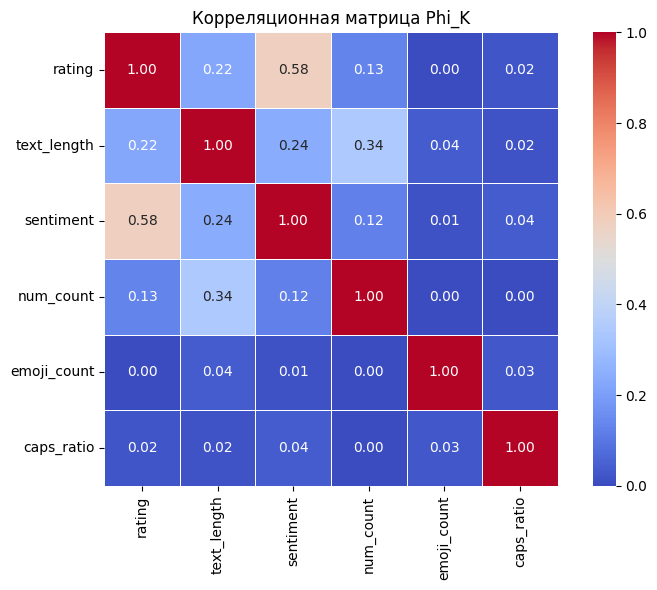

In [ ]:
# Матрица корреляции Phi_K
features = ['rating', 'text_length', 'sentiment', 'num_count', 'emoji_count', 'caps_ratio']
phik = new_df[features].phik_matrix(interval_cols=[c for c in features if c != 'rating'])

plt.figure(figsize=(8, 6))
sns.heatmap(
    phik,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=0, vmax=1,
    square=True,
    linewidths=.5
)

plt.title('Корреляционная матрица Phi_K')
plt.tight_layout()
plt.show()

**Промежуточные выводы:** Анализ матрицы Phi_K показал, что самая сильная зависимость наблюдается между рейтингом и семантической тональностью (0.58). Достаточно очевидная связь, но, как мы видели, не всегда это правило соблюдается. Умеренная связь прослеживается между рейтингом и длиной текста (0.22) и количеством чисел (0.13). Остальные признаки (эмодзи, капс) показали близкую к нулю корреляцию с целевой переменной.

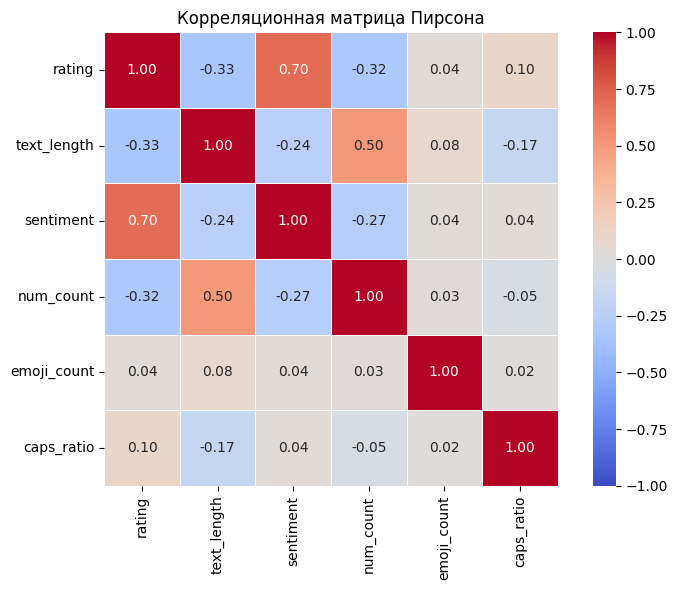

In [ ]:
# Матрица корреляции Пирсона
plt.figure(figsize=(8, 6))
sns.heatmap(
    new_df[['rating', 'text_length', 'sentiment', 'num_count', 'emoji_count', 'caps_ratio']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    square=True,
    linewidths=.5
)

plt.title('Корреляционная матрица Пирсона')
plt.tight_layout()
plt.show()

**Промежуточные выводы:** Матрица Пирсона показывает еще более сильную прямую корреляцию между рейтингом и тональностью - 0.70. Это классическая прямая зависимость: чем позитивнее текст, тем выше оценка. Интересно, что длина текста имеет слабую отрицательную связь с рейтингом (-0.33) и с количеством цифр (-0.32). Это логично: человеку, котор ставит низкие оценки, есть что рассказать и, скорее всего, в тексте использует информацию о времени и ценах в заведении, чтобы описать причину своего недовольства. Довольный покупатель зачастую пишет короткий фидбек и ставит высокую оценку.

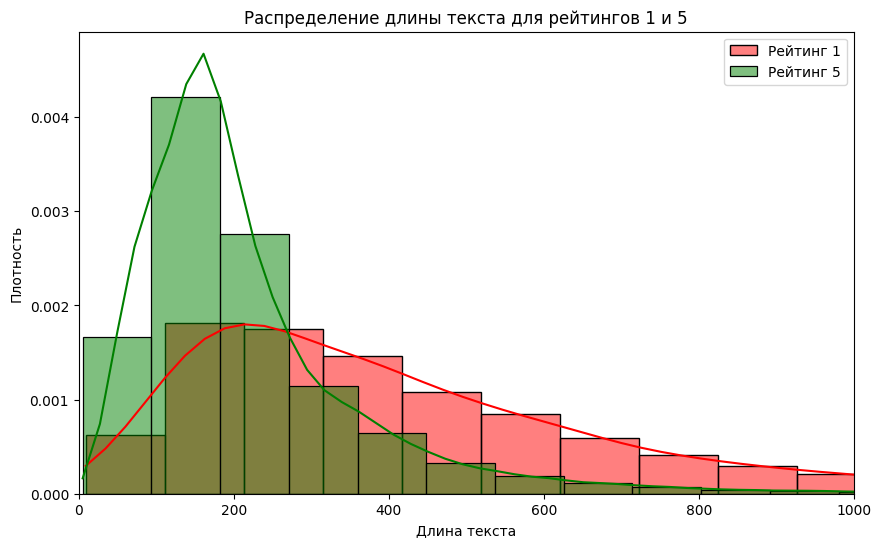

In [ ]:
# Распределение метрик в зависимости с рейтингом
plt.figure(figsize=(10, 6))
sns.histplot(new_df[new_df['rating'] == 1]['text_length'], color='red', label='Рейтинг 1', kde=True, stat='density', alpha=0.5, bins=50)
sns.histplot(new_df[new_df['rating'] == 5]['text_length'], color='green', label='Рейтинг 5', kde=True, stat='density', alpha=0.5, bins=50)
plt.xlim(0, 1000)
plt.xlabel('Длина текста')
plt.ylabel('Плотность')
plt.title('Распределение длины текста для рейтингов 1 и 5')
plt.legend()
plt.show()

**Промежуточные выводы:** Гистограмма плотности наглядно демонстрирует, что отзывы с рейтингом 1 имеют "длинный хвост" и смещены вправо, в то время как отзывы с рейтингом 5 сконцентрированы в узком пике вокруг 150-200 символов. Это объясняется как раз в предыдущем выводе.

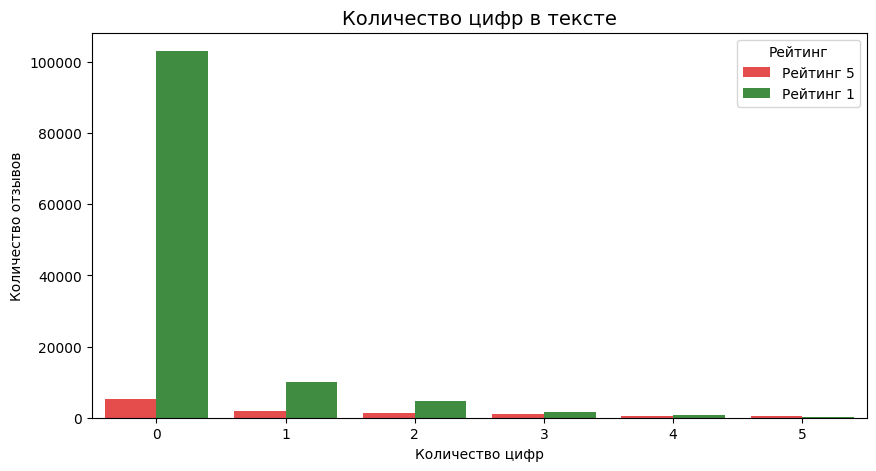

In [ ]:
# Распределение метрик в зависимости с рейтингом
plt.figure(figsize=(10, 5))
subset_nums = new_df[(new_df['num_count'] <= 5) & ((new_df['rating'] == 1) | (new_df['rating'] == 5))]
sns.countplot(data=subset_nums, x='num_count', hue='rating', palette={1: 'red', 5: 'green'}, alpha=0.8)
plt.title('Количество цифр в тексте', fontsize=14)
plt.xlabel('Количество цифр')
plt.ylabel('Количество отзывов')
plt.legend(title='Рейтинг', labels=['Рейтинг 5', 'Рейтинг 1'])
plt.show()

**Промежуточные выводы:** Столбчатая диаграмма показывает, что подавляющее большинство отзывов, как с рейтингом 1, так и с 5, вообще не содержат цифр (в целом такого среза данных достаточно, потому что больше 5 цифр в тексте не увидишь, судя по графику). Однако, если цифры встречаются, то у негативных отзывов их больше, чем у позитивных. Это было объяснено также в корреляционном анализе.

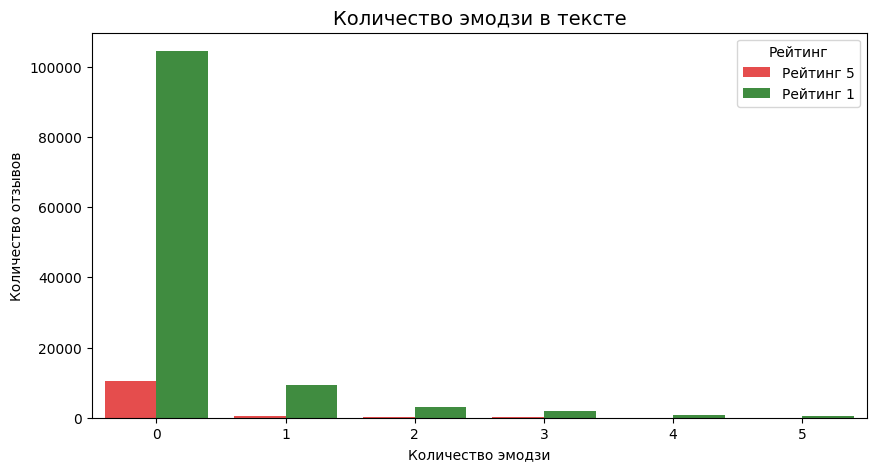

In [ ]:
# Распределение метрик в зависимости с рейтингом
plt.figure(figsize=(10, 5))
subset_emoji = new_df[(new_df['emoji_count'] <= 5) & ((new_df['rating'] == 1) | (new_df['rating'] == 5))]
sns.countplot(data=subset_emoji, x='emoji_count', hue='rating', palette={1: 'red', 5: 'green'}, alpha=0.8)
plt.title('Количество эмодзи в тексте', fontsize=14)
plt.xlabel('Количество эмодзи')
plt.ylabel('Количество отзывов')
plt.legend(title='Рейтинг', labels=['Рейтинг 5', 'Рейтинг 1'])
plt.show()

**Промежуточные выводы:** Абсолютное большинство отзывов обходится без эмоджи. Тем не менее, график показывает интересный тренд: если эмоджи используются, то в негативных отзывах их количество немного выше, чем в позитивных.

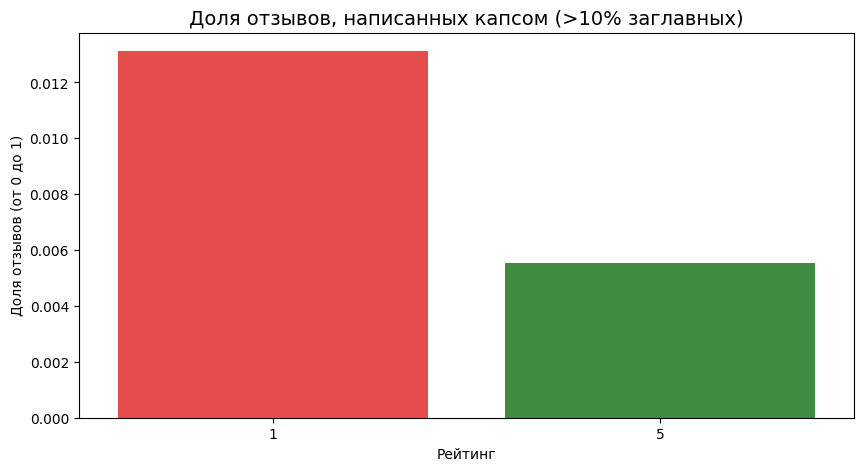

In [ ]:
# Распределение метрик в зависимости с рейтингом
plt.figure(figsize=(10, 5))
new_df['has_caps'] = new_df['caps_ratio'] > 0.1
sns.barplot(data=new_df[new_df['rating'].isin([1, 5])], x='rating', y='has_caps', palette={'1': 'red', '5': 'green'}, errorbar=None, alpha=0.8)
plt.title('Доля отзывов, написанных капсом (>10% заглавных)', fontsize=14)
plt.xlabel('Рейтинг')
plt.ylabel('Доля отзывов (от 0 до 1)')
plt.show()

**Промежуточные выводы:** График показывает, что доля отзывов, написанных с активным использованием капса, среди негативных оценок более чем в два раза выше, чем среди позитивных.

## **Итоговый вывод**

**Подсветим основные моменты из разведочного анализа данных.**

**Данные:**

В ходе EDA был сформирован срез для исследования, содержащий данные в интересующей для нас области: из исходного массива вручную был выделен пул из 48 категорий, относящихся к ритейлу и общепиту, а финальный датасет составил треть от исходного.

**Качество данных и анализ целевой переменной:**

Анализ подтвердил пригодность данных для дальнейшего моделирования. Выявлены лишь незначительные пропуски и типичные дубликаты в текстах отзывов, что не является критичным. Однако выявлен сильный дисбаланс классов: подавляющее большинство отзывов (около 84%) имеют оценку 4 и 5, тогда как негативные оценки составляют не более 15%. Из этого следует, что при обучении нам нужно использовать методы для балансировки данных.

**Анализ текстовых паттернов и признаков:**

Исследование текстов показало, что медианная длина комментария составляет 192 символа. При этом выявлена обратная связь между длиной текста и рейтингом (коэффициент корреляции -0.33), а также количеством цифр и рейтингом (-0.32). Причиной тому: пользователи склонны подробно описывать негативный опыт с указанием времени, цен, количества персонала и оставлять короткие формальные отзывы при высоких оценках. Анализ биграмм подтвердил наличие типичных слов-маркеров для разных рейтингов.

Дополнительные признаки, такие как использование эмоджи и капса, показали близкую к нулю корреляцию с целевой переменной, однако "выкидывать" эти данные не нужно: можно воспользоваться алгоритмами, позволяющие выявлять более тонкие взаимосвязи между данными и протестировать созданные переменные.

**Семантический анализ и поиск аномалий:** Ключевым инструментом для анализа тональности была выбрана предобученная модель RuBERT. Корреляционный анализ на основе коэффициентов корреляции Пирсона показал сильную прямую зависимость между семантической тональностью текста и рейтингом (0.70) - не всегда оценка и семантика отзыва коррелируют, но в большинстве случаев это действительно так.

Модель RuBERT достаточно проста и удобна в использовании, однако излишне чувствительна к отдельным словам и не всегда корректно распознает смешанную тональность, т. е. кейсы, где содержатся сарказм или конструктивная критика без лишнего негатива. При обучении будут рассмотрены иные методы анализа тональности текста либо будут применены иные гиперпараметры для того же RuBERT для получения информации о тональности текста. Лингвистический анализ с использованием словаря "Картаслов" подтвердил, что около 5% текстов содержат одновременно и комплименты, и критику, что может приводить к ошибкам в определении тональности отзыва.

Кроме того, в данных были обнаружены явные аномалии, когда тональность текста не совпадает с рейтингом отзыва. Для их выявления классического текстового анализа недостаточно, так как несовпадение оценки и текста (в том числе через эмодзи) требует более комплексного подхода. По этой причине целесообразно использовать модели, которые объединят семантический анализ текста с применением дополнительных фичей.